__This notebook contains examples of different ways to represent orientation of an object (an arrow in this case) in simulations!__ 

__First off: Rotation matrix!__

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import numpy.linalg as npla


#Here we first define the arrow. It is a 2D object which we will rotate in 3d space. 

# 2D arrow outline by defining a sequence of points (x, y)
outline_2d = np.array([
    [-1.5, -0.35],
    [ 0.4, -0.35],
    [ 0.4, -0.70],
    [ 1.4,  0.00],
    [ 0.4,  0.70],
    [ 0.4,  0.35],
    [-1.5,  0.35]
])

# Add z = 0 to every vertex
arrow_3d = np.column_stack((
    outline_2d,
    np.zeros(len(outline_2d))
))



Below I define a function that that plots an arrow in a world frame with the co-rotating body frame indicated by different colored vectors. 

In [69]:
def plot_arrow(arrow_3d, orientation):

    
    orientation = orientation/npla.norm(orientation, axis= 0)

    #Set arrow orientation
    arrow_3d = (orientation @ arrow_3d.T).T

    # Create 3D figure
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(111, projection="3d")

    # Plot the rotated arrow using its full 3D coordinates
    arrow = Poly3DCollection(
        [arrow_3d],
        facecolors="cornflowerblue",
        edgecolors="black",
        alpha=0.8
    )
    ax.add_collection3d(arrow)

    # Plot the object's local coordinate axes
    axis_length = 1.5
    origin = np.zeros(3)

    # Create the three local coordinate arrows
    colors = ["red", "green", "blue"]
    labels = ["Body X", "Body Y", "Body Z"]

    axis_arrows = [
        ax.quiver(
            *origin,
            *(orientation[:, i] * axis_length),
            color=colors[i],
            label=labels[i]
        )
        for i in range(3)
    ]

    # Plot settings
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.set_zlim(-2, 2)

    ax.set_xlabel("World X")
    ax.set_ylabel("World Y")
    ax.set_zlabel("World Z")

    ax.set_box_aspect((1, 1, 1))
    ax.legend()
    ax.set_title("Arrow and orientation")

    return fig, ax, arrow, axis_arrows

Below I define the intial orientation of the the arrow and use the plot function to visualize it. Remeber from the lecture that the rotation matrix may be expressed:
\begin{align}
    R = \begin{bmatrix} \hat e_{1}^{b} & \hat e_{2}^{b} & \hat e_{3}^{b} \end{bmatrix}
\end{align}
where $\hat e_{i}^{b}$ is the $i$:th component of the body frame in the world frame. 

In this example I want to the initial orientation of the arrow to be aligned with the world frame, and therefore I choose that
$\hat e_{i}^{b} = e_{i}$ which gives us a rotation matrix that is an identity matrix. But feel free to change the initial orientation. 

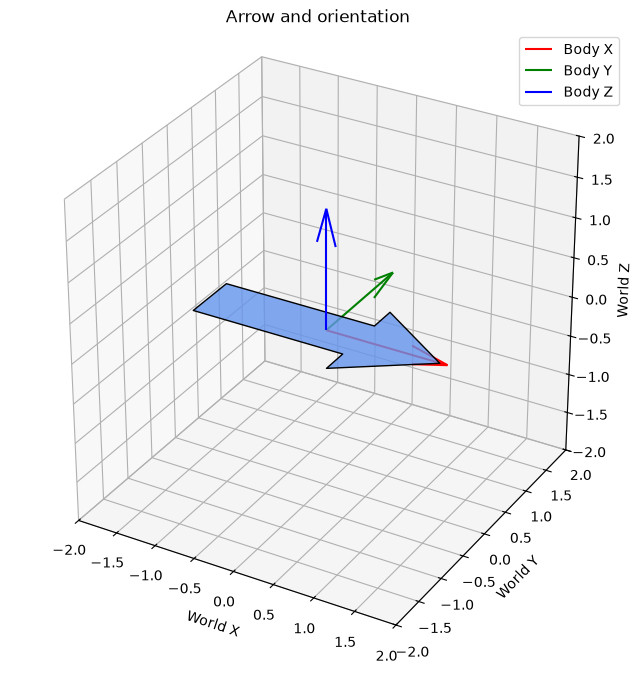

In [78]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# Initial orientation
R_ini = np.array([
        [1,    0,  0],
        [0,  1,    0],
        [0, 0,  1]
    ])



fig, ax, arrow, axis_arrows = plot_arrow(arrow_3d, R_ini)


plt.show()



We will now rotate this arrow about the z-axis at a rate of $\pi/2$ rad/s. We will update the orientation of the arrow by numerical integration using Explicit Euler ($R_{k+1} = R_k + \dot R_k \Delta t$). We start by defining the angular velocity matrix 
\begin{align}
    \bar \omega = \begin{bmatrix} 0 \\ 0 \\ \pi/2 \end{bmatrix}
\end{align}

Remember that the time derivative of the rotation matrix (the orientation of the arrow in our case) is given by 

\begin{align}
    \dot R = [\omega_{\times}]R
\end{align}
where 
\begin{align}
    [\omega_{\times}] = \begin{bmatrix} 0 & -\omega_z & \omega_y \\
                                        \omega_z & 0 & -\omega_x \\
                                        -\omega_y & \omega_x & 0\end{bmatrix}  = \begin{bmatrix} 0 & -\pi/2 & 0 \\
                                        \pi/2 & 0 & 0 \\
                                        0 & 0 & 0\end{bmatrix}
\end{align}

This of course represent a rotation about the z-axis of the world frame. Feel free to change $\bar \omega$!



In [79]:
def skew(v):
    return np.array([
        [0,    -v[2],  v[1]],
        [v[2],  0,    -v[0]],
        [-v[1], v[0],  0]
    ])

omega = [0, 0, np.pi/2]

skew_omega = skew(omega)

print(skew_omega) 

[[ 0.         -1.57079633  0.        ]
 [ 1.57079633  0.          0.        ]
 [ 0.          0.          0.        ]]


Below I have first defined a function for updating the orientation using explicit euler. What then follows is the code for animating the arrow. You do not have to understand this part of code :)

In [80]:
#Explicit euler time integration 
def update_R(R):
    R = R + dt * skew_omega @ R
    return R

def create_animation(R_initial):

    R = R_initial.copy()

    def animate(frame):
        nonlocal R

        R = update_R(R)

        rotated_arrow = (R @ arrow_3d.T).T
        arrow.set_verts([rotated_arrow])

        # Update the local coordinate arrows
        for i, color in enumerate(["red", "green", "blue"]):

            axis_arrows[i].remove()

            axis_arrows[i] = ax.quiver(
                0, 0, 0,
                *(R[:, i] * 1.5),
                color=color
            )

        return arrow,

    ani = FuncAnimation(
        fig,
        animate,
        frames=100,
        interval=20,
        blit=False
    )

    return ani

#Set time step size 
dt = 0.01 

ani = create_animation(R_ini)

HTML(ani.to_jshtml())

__Next up: Euler Angles!__

As you have seen in the lecture, the way a general rotation is described in Euler angles is by treating it as three sequential rotations about three pairwise orthogonal axes. In this example, I will use the Tait-Bryan ZYX convention (Yaw-Pitch-Roll). With this convention, the rotation matrix is given by:

\begin{align}
    R = R_{z}(\psi)R_y(\theta)R_x(\phi) = \begin{bmatrix}
\cos\psi & -\sin\psi & 0 \\
\sin\psi & \cos\psi & 0 \\
0 & 0 & 1
\end{bmatrix}
\begin{bmatrix}
\cos\theta & 0 & \sin\theta \\
0 & 1 & 0 \\
-\sin\theta & 0 & \cos\theta
\end{bmatrix}
\begin{bmatrix}
1 & 0 & 0 \\
0 & \cos\phi & -\sin\phi \\
0 & \sin\phi & \cos\phi
\end{bmatrix}
\end{align}

where $\psi$ is the orientation angle about the world frame z-axis, $\theta$ about world frame y-axis, $\phi$ about the world frame x-axis. The angles are stored in a vector
\begin{align}
    \Omega = \begin{bmatrix}\phi \\ \theta \\ \psi \end{bmatrix}
\end{align}

I will first show how the rotations are applied sequentially, and then move on to an example very similar to the the last section where we will rotate the arrow at an angular velocity using the Euler angles. 



__Sequential Rotations__

Below we define a function that translates Euler angles into a rotation matrix as described above.

In [83]:
#Here I define a function that translates Euler angles to a rotation matrix!

def euler_to_R(phi, theta, psi):

    Rx = np.array([
        [1, 0, 0],
        [0, np.cos(phi), -np.sin(phi)],
        [0, np.sin(phi), np.cos(phi)]
    ])

    Ry = np.array([
        [np.cos(theta), 0, np.sin(theta)],
        [0, 1, 0],
        [-np.sin(theta), 0, np.cos(theta)]
    ])

    Rz = np.array([
        [np.cos(psi), -np.sin(psi), 0],
        [np.sin(psi), np.cos(psi), 0],
        [0, 0, 1]
    ])

    return Rz @ Ry @ Rx

You do not have to understand the cell below since it contains the code necessary to animate the sequential rotations. 

In [101]:
def create_sequential_animation(angles_ini, angles_final):

    # Start with the initial orientation
    R_initial = euler_to_R(*angles_ini)

    fig, ax, arrow, axis_arrows = plot_arrow(
        arrow_3d, R_initial
    )

    # Add textbox to display the current rotation
    rotation_text = ax.text2D(
        0.05, 0.95,
        "",
        transform=ax.transAxes,
        fontsize=12,
        verticalalignment="top",
        bbox=dict(
            boxstyle="round",
            facecolor="white",
            alpha=0.9
        )
    )

    def animate(frame):

        # Determine which rotation we are currently performing
        stage = frame // 30
        progress = (frame % 30 + 1) / 30

        if stage == 0:
            # First rotate about X (Roll)
            phi_current = angles_ini[0] + progress * (angles_final[0] - angles_ini[0])
            theta_current = angles_ini[1]
            psi_current = angles_ini[2]
            title = "Step 1: Roll about X-axis"

        elif stage == 1:
            # Then rotate about Y (Pitch)
            phi_current = angles_final[0]
            theta_current = angles_ini[1] + progress * (angles_final[1] - angles_ini[1])
            psi_current = angles_ini[2]
            title = "Step 2: Pitch about Y-axis"

        else:
            # Finally rotate about Z (Yaw)
            phi_current = angles_final[0]
            theta_current = angles_final[1]
            psi_current = angles_ini[2] + progress * (angles_final[2] - angles_ini[2])
            title = "Step 3: Yaw about Z-axis"

        # Calculate the current orientation
        R = euler_to_R(
            phi_current,
            theta_current,
            psi_current
        )

        # Update textbox
        rotation_text.set_text(title)

        # Update arrow
        rotated_arrow = (R @ arrow_3d.T).T
        arrow.set_verts([rotated_arrow])

        # Update local coordinate axes
        for i, color in enumerate(["red", "green", "blue"]):

            axis_arrows[i].remove()

            axis_arrows[i] = ax.quiver(
                0, 0, 0,
                *(R[:, i] * 1.5),
                color=color
            )

        ax.set_title("Sequential Euler rotations")

        return arrow, rotation_text

    ani = FuncAnimation(
        fig,
        animate,
        frames=90,
        interval=50,
        blit=False
    )

    return ani

Here, we define the initial angles and final angles for the demonstration of the sequantial rotations. Play around with the angles!! What happens when $\theta_f = \pi/2$? Why?

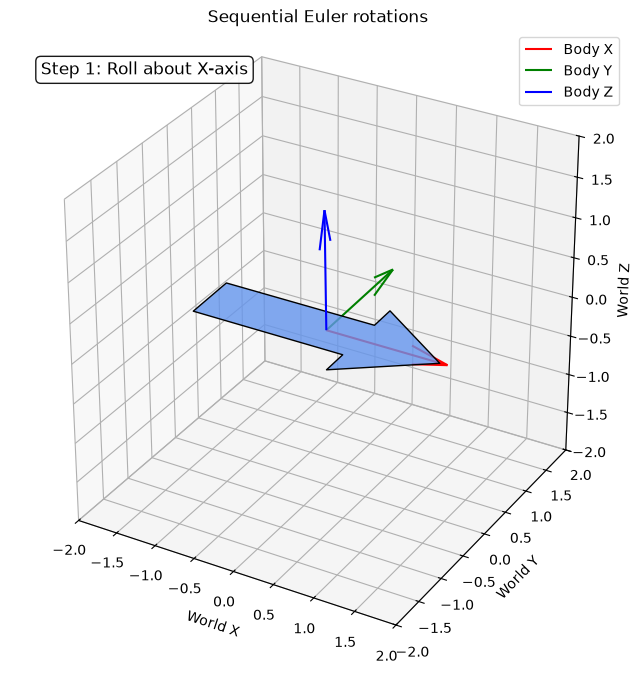

In [ ]:
# Choose the initial angles for the demonstration
phi_ini = 0   #Roll (about x-axis)
theta_ini = 0  #Pitch (about y-axis)
psi_ini = 0   #Yaw  (about z-axis)

angles_ini = [phi_ini, theta_ini, psi_ini]  

#Choose final angles
phi_final = np.pi/4 
theta_final = np.pi/2 
psi_final = np.pi/4 

angles_final = [phi_final, theta_final, psi_final]

ani_sequential = create_sequential_animation(
    angles_ini, angles_final
)

HTML(ani_sequential.to_jshtml())

__Euler Angles and angular velocity__

Next, we need to review how to update Euler angles. Recall from the lecture that since $\omega = \frac{d\Omega}{dt}$, we can express $\omega$ as 

\begin{align}
    &\omega = G\dot \Omega \\
    \implies &\dot \Omega = G^{-1}\omega
\end{align}

in order to update the position using Explicit Euler we need to find $G^{-1}$ in order to find $\dot \Omega$. However, the process of deriving $G^{-1}$ is somewhat cumbersome (it involves differentiation $R$ using the product rule and exploiting that $[\omega_{\times}] = \dot R R^T$), so I will simply give you the expression:

\begin{align}
    G^{-1}
    =
    \begin{bmatrix}
    \frac{\cos\psi}{\cos\theta} &
    \frac{\sin\psi}{\cos\theta} & 0\\
    -\sin\psi & \cos\psi & 0\\
    \cos\psi\tan\theta & \sin\psi\tan\theta & 1
    \end{bmatrix}
\end{align}

What you will see in the coming animation, the rotations will appear smooth and not done in sequence. This is because the sequential rotations are combined into one smaller rotation that is performed every time-step. 





In [103]:
#Here I define a function that updates the Euler Angles using G^-1
def update_euler(phi, theta, psi, omega, dt):

    G_inv = np.array([
        [np.cos(psi)/np.cos(theta),
         np.sin(psi)/np.cos(theta),
         0],

        [-np.sin(psi),
         np.cos(psi),
         0],

        [np.cos(psi)*np.tan(theta),
         np.sin(psi)*np.tan(theta),
         1]
    ])

    #euler_dot contains the time derivatives of the Euler angles. 
    euler_dot = G_inv @ omega

    phi += dt * euler_dot[0]
    theta += dt * euler_dot[1]
    psi += dt * euler_dot[2]

    return phi, theta, psi

In order to make the comparison between these two methods meaningful, I choose to implement another concept from the lecture, which is obtaining Euler Angles from a rotation matrix! The angles are found using the equations: 
\begin{align}
    &\phi = \operatorname{atan2}\left(
    \frac{R_{32}}{\sin\theta},
    -\frac{R_{31}}{\sin\theta}
    \right) \\
    &\theta = \operatorname{atan2}\left(
    \sqrt{R_{31}^2+R_{32}^2},
    R_{33}
    \right) \\
    & \psi = \operatorname{atan2}\left(
    \frac{R_{21}}{\sin\theta},
    \frac{R_{11}}{\sin\theta}
    \right)
\end{align}

I now define a function that extracts these angles from a given rotation matrix. I do this so that we we can obtain the angles correspoding to the initial rotation matrix defined in the last section. In that way, you only have to change the initial orientation in that part of the code :)

In [85]:
def R_to_euler(R):

    theta = np.arctan2(
        np.sqrt(R[2, 0]**2 + R[2, 1]**2),
        R[2, 2]
    )

    if np.abs(np.sin(theta)) < 1e-8:
        phi = 0.0
        psi = np.arctan2(R[1, 0], R[0, 0])
    else:
        phi = np.arctan2(R[2, 1], -R[2, 0])
        psi = np.arctan2(R[1, 0], R[0, 0])

    return phi, theta, psi

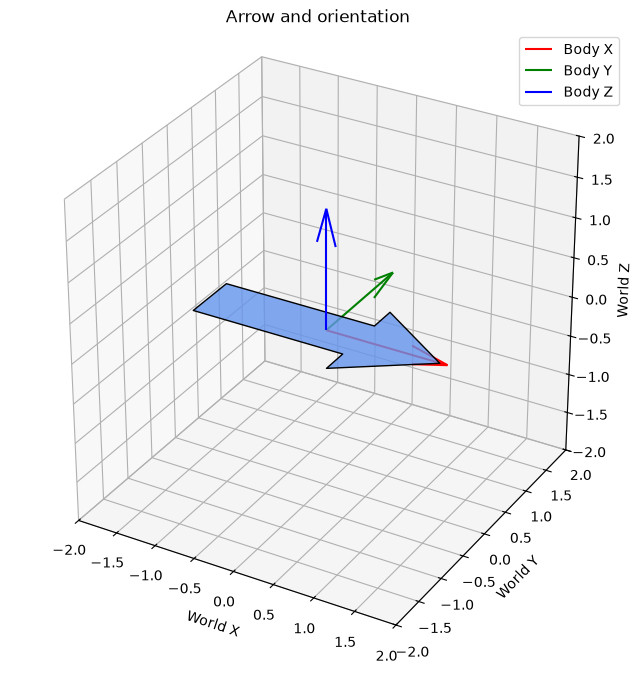

In [ ]:
#The code below is merely an example, as you can tell I 
# transform a rotation matrix into angles and then back into a rotation matrix.
#That is of course redudant, but for the sake of learning I wanted to show you how to do this in practice :)

phi_ini, theta_ini, psi_ini = R_to_euler(R_ini)

R_ini_euler = euler_to_R(phi_ini, theta_ini, psi_ini)

fig, ax, arrow, axis_arrows = plot_arrow(arrow_3d, R_ini_euler)

plt.show()

In [106]:
#You do not have to understand this part, it is code for animation.

def create_euler_animation(phi_initial, theta_initial, psi_initial, omega, dt):

    phi = phi_initial
    theta = theta_initial
    psi = psi_initial

    def animate(frame):
        nonlocal phi, theta, psi

        # Update Euler angles
        phi, theta, psi = update_euler(
            phi, theta, psi, omega, dt
        )

        # Calculate orientation matrix
        R = euler_to_R(phi, theta, psi)

        # Update arrow
        rotated_arrow = (R @ arrow_3d.T).T
        arrow.set_verts([rotated_arrow])

        # Update local coordinate axes
        for i, color in enumerate(["red", "green", "blue"]):

            axis_arrows[i].remove()

            axis_arrows[i] = ax.quiver(
                0, 0, 0,
                *(R[:, i] * 1.5),
                color=color,
                label=["Local X", "Local Y", "Local Z"][i]
            )

        return arrow,

    ani = FuncAnimation(
        fig,
        animate,
        frames=100,
        interval=20,
        blit=False
    )

    return ani

In [107]:
omega = np.array([0, 0, np.pi/2])  # rad/s
dt = 0.01

ani = create_euler_animation(
    phi_ini,
    theta_ini,
    psi_ini,
    omega,
    dt
)

HTML(ani.to_jshtml())